# Time Breakdown — 32K

比较 batch 32/64/96/128 下的 Quest、Twilight 和 GAS。依次运行下面两个代码单元格，即可绘图并导出 PDF、PNG 和 CSV。

数据来源：用户提供的每步分项数据（2026-11-14），亦见同目录 `实验记录.md` 的“1114 合成 Union Budget 测试”（32K 合成预算场景）。第二个代码单元格顶部的 `BREAKDOWN_US` 保留原始数值，维度为 `[batch, component]`，单位 **μs**；绘图统一换算为 **ms**。缺失分项（—）按 0 处理，不应用额外缩放。

| 绘图组件 | 数据含义 |
|---|---|
| Top-k selector | Quest selector |
| Top-p pruning | INT4 estimator + Top-p |
| Group-Aware Refinement | GAS |
| Sparse Attention | Attention |

堆叠条长度为以上四部分之和，表示分项投影耗时。原表“投影合计”单独保存在 `REPORTED_TOTAL_US` 中。Quest 和 Twilight 的合计均与分项和一致；GAS 的分项和为 1293.56、2464.91、3661.59、4841.19 μs，原表合计分别多出 4.61、8.06、9.98、17.16 μs。绘图不将这些差值分摊到任何组件。

运行后更新同目录 `time_breakdown.pdf`、`time_breakdown.png` 和 `time_breakdown_data.csv`。CSV 同时保存五个原始分项（μs）、四个绘图组件（ms）、分项合计及原表合计与分项和之差（μs）。


In [3]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pad_inches": 0.1}
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
import numpy as np
from IPython.display import display

TEAL, BLUE, ORANGE, GRAY, INK = "#008b87", "#4f7192", "#c76524", "#737b81", "#243136"

def setup_style():
    for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf", "Times New Roman Italic.ttf"):
        path = Path("/System/Library/Fonts/Supplemental") / name
        if path.exists():
            font_manager.fontManager.addfont(str(path))
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"], "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 12, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": .6, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK, "savefig.facecolor": "white", "hatch.linewidth": 0.3})

def axis_style(ax, grid_axis="both"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(width=.6, length=2, pad=2)
    ax.grid(axis=grid_axis, color="#dce2e5", linewidth=.45, zorder=0)
    ax.set_axisbelow(True)

setup_style()

Saved figures and component data to: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig8-TimeBreakdown/bk_tested


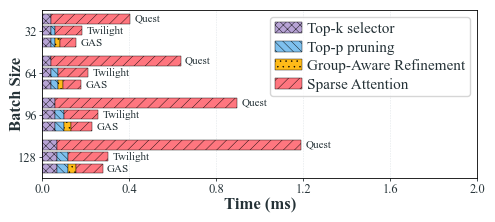

In [10]:
# Editable per-step measurements, in microseconds (2026-11-14).
# Array axes: [batch, component]; 32K synthetic union-budget scenario.
# Raw component order: Quest selector, INT4 estimator, Top-p, GAS, Attention.
# Source: user-supplied table / 实验记录.md, “1114 合成 Union Budget 测试”.
BREAKDOWN_BATCHES = (32, 64, 96, 128)
BREAKDOWN_LENGTH = 32768
BREAKDOWN_METHODS = ("quest", "quest_twi", "gas")
BREAKDOWN_LABELS = {"quest": "Quest", "quest_twi": "Twilight", "gas": "GAS"}
BREAKDOWN_COMPONENT_KEYS = (
    "quest_selector_us", "int4_estimator_us", "top_p_us", "gas_us", "attention_us")

BREAKDOWN_US = {
    # "quest": np.array([
    #     [256.27, 0.00, 0.00, 0.00, 2251.26],
    #     [533.81, 0.00, 0.00, 0.00, 3482.88],
    #     [783.47, 0.00, 0.00, 0.00, 4827.78],
    #     [1054.61, 0.00, 0.00, 0.00, 6272.00],
    # ]),
    # "quest_twi": np.array([
    #     [256.07, 158.28, 366.70, 0.00, 1216.64],
    #     [489.32, 278.58, 706.67, 0.00, 1904.00],
    #     [756.53, 415.18, 1071.51, 0.00, 2611.20],
    #     [1018.73, 561.90, 1383.96, 0.00, 3389.18],
    # ]),
    # "gas": np.array([
    #     [256.07, 158.28, 366.70, 488.19, 24.32],
    #     [489.32, 278.58, 706.67, 953.73, 36.61],
    #     [756.53, 415.18, 1071.51, 1366.40, 51.97],
    #     [1018.73, 561.90, 1383.96, 1811.58, 65.02],
    # ]),
    "quest": np.array([
        [37.60, 0.00, 0.00, 0.00, 367.51],
        [41.30, 0.00, 0.00, 0.00, 593.90],
        [57.50, 0.00, 0.00, 0.00, 838.58],
        [69.30, 0.00, 0.00, 0.00, 1121.45],
    ]),
    "quest_twi": np.array([
        [37.60, 17.85, 3.60, 0.00, 124.64],
        [41.30, 21.63, 8.55, 0.00, 139.19],
        [57.50, 26.73, 14.63, 0.00, 158.85],
        [69.30, 30.11, 19.12, 0.00, 183.08],
    ]),
    "gas": np.array([
        [37.60, 17.85, 3.60, 21.09, 75.47],
        [41.30, 21.63, 8.55, 25.67, 82.64],
        [57.50, 26.73, 14.63, 31.33, 99.89],
        [69.30, 30.11, 19.12, 36.12, 123.21]]
    ),

}

# Preserve the supplied totals separately; bar lengths use component sums.
REPORTED_TOTAL_US = {
    "quest": np.array([2507.53, 4016.69, 5611.25, 7326.61]),
    "quest_twi": np.array([1997.69, 3378.57, 4854.42, 6353.77]),
    "gas": np.array([1298.17, 2472.97, 3671.57, 4858.35]),
}
BREAKDOWN_PLOT_KEYS = (
    "top_k_selector_ms", "top_p_pruning_ms", "group_aware_refinement_ms",
    "sparse_attention_ms")


def plotting_components(component_us):
    """Merge INT4 estimator + Top-p and convert all four components to ms."""
    values = {}
    for method, raw in component_us.items():
        raw = np.asarray(raw, dtype=float)
        values[method] = np.column_stack((
            raw[:, 0], raw[:, 1] + raw[:, 2], raw[:, 3], raw[:, 4])) / 1000.0
    return values


# Appearance settings shared by bars and legend swatches.
BREAKDOWN_HATCH_COLOR = "black"  # 内部纹理颜色
BREAKDOWN_EDGE_WIDTH = 0.3        # 色块边框宽度；0 表示不显示边框

# Component key, legend label, fill color, and hatch pattern.
BREAKDOWN_STYLES = [
    ("top_k_selector_ms", "Top-k selector", "#B7A3D5", "xxxx"),
    ("top_p_pruning_ms", "Top-p pruning", "#7EC0EE", "\\" * 4),
    ("group_aware_refinement_ms", "Group-Aware Refinement", "#FFBB19", "..."),
    ("sparse_attention_ms", "Sparse Attention", "#ff767f", "///"),
]


def time_breakdown_figure(component_us, batches=BREAKDOWN_BATCHES,
                          methods=BREAKDOWN_METHODS, styles=None):
    """Plot four per-step components in ms for the 32K scenario."""
    styles = BREAKDOWN_STYLES if styles is None else styles
    values = {method: np.asarray(component_us[method], dtype=float) for method in methods}
    for value in values.values():
        assert value.shape == (len(batches), len(BREAKDOWN_COMPONENT_KEYS))
        assert np.isfinite(value).all() and (value >= 0).all()
    values = {method: value for method, value in plotting_components(component_us).items()
              if method in methods}
    max_total = max(np.sum(value, axis=1).max() for value in values.values())
    upper = np.ceil(max_total * 1.38)
    # 画布大小
    fig, ax = plt.subplots(figsize=(5,3))
    fig.subplots_adjust(left=.12, right=.99, top=.75, bottom=.19)
    # 设置柱之间的间隙宽度
    offsets = (np.arange(len(methods)) - (len(methods)-1)/2) * .28
    axis_style(ax, "x")
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.spines["left"].set_zorder(10)  # y 轴边框置于柱状色块上方
    ax.grid(axis="x", color="#D3D9DE", linewidth=.45, linestyle=":")
    for i, batch in enumerate(batches):
        for method, offset in zip(methods, offsets):
            components = values[method][i]
            left = 0.0
            for key, label, color, hatch in styles:
                value = components[BREAKDOWN_PLOT_KEYS.index(key)]
                if value == 0:
                    continue
                ax.barh(i + offset, value, height=.22, left=left, color=color,
                        hatch=hatch, edgecolor=BREAKDOWN_HATCH_COLOR,
                        linewidth=BREAKDOWN_EDGE_WIDTH, zorder=3)
                left += value
            ax.annotate(BREAKDOWN_LABELS[method], xy=(left, i + offset),
                        xytext=(3, 0), textcoords="offset points",
                        va="center", ha="left", fontsize=8, color=INK)
    ax.set(
        xlim=(0, upper),
        ylim=(len(batches)-.5, -.5),
        yticks=np.arange(len(batches)),
        yticklabels=batches,
        xticks=np.arange(0, upper + .01, 0.4)  # 每隔 2 ms 显示一个刻度
    )
    ax.tick_params(axis="both", labelsize=9, pad=2)
    ax.set_xlabel("Time (ms)", labelpad=1.2,
                  fontdict={"size": 12, "weight": "bold", "fontfamily": "Times New Roman"})
    ax.set_ylabel("Batch Size", labelpad=-5,
                  fontdict={"size": 12, "weight": "bold", "fontfamily": "Times New Roman"})
    ax.legend(
        [Patch(facecolor=c, edgecolor=BREAKDOWN_HATCH_COLOR, hatch=h,
               linewidth=BREAKDOWN_EDGE_WIDTH)
         for _, _, c, h in styles],
        [label for _, label, _, _ in styles],
        loc="upper right",
        ncol=1,
        labelspacing=0.3,      # 行间距，默认 0.5
        handletextpad=0.3,     # 色块与文字的水平间距，默认 0.8
        borderpad=0.3,         # 图例内容与边框的间距，默认 0.4
        handlelength=1.8,      # 色块长度，默认 2.0
        frameon=True,
        prop={"family": "Times New Roman", "size": 11},
    )
    return fig


setup_style()
if "fig_breakdown" in globals():
    plt.close(fig_breakdown)
fig_breakdown = time_breakdown_figure(BREAKDOWN_US)

# Save next to this notebook when run from its directory or a project ancestor.
if "__file__" in globals():
    OUTPUT_DIR = Path(__file__).resolve().parent
else:
    _here = Path.cwd().resolve()
    _candidates = (
        _here,
        _here / "bk_tested",
        _here / "fig8-TimeBreakdown/bk_tested",
        _here / "会用到的论文图与复现/fig8-TimeBreakdown/bk_tested",
    )
    OUTPUT_DIR = next(q for q in _candidates if (q / "TimeBreakdown.ipynb").exists())
fig_breakdown.savefig(OUTPUT_DIR / "time_breakdown.pdf", bbox_inches="tight")
fig_breakdown.savefig(OUTPUT_DIR / "time_breakdown.png", dpi=220, bbox_inches="tight")

# Export original measurements, the four plotted components, and both totals.
plot_values = plotting_components(BREAKDOWN_US)
with (OUTPUT_DIR / "time_breakdown_data.csv").open("w", newline="", encoding="utf-8") as handle:
    fields = ["batch_size", "length", "method", *BREAKDOWN_COMPONENT_KEYS,
              *BREAKDOWN_PLOT_KEYS, "component_total_us", "reported_total_us",
              "reported_minus_components_us", "plotted_total_ms"]
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    for i, batch in enumerate(BREAKDOWN_BATCHES):
        for method in BREAKDOWN_METHODS:
            raw = BREAKDOWN_US[method][i]
            plotted = plot_values[method][i]
            component_total = float(raw.sum())
            reported_total = float(REPORTED_TOTAL_US[method][i])
            row = {"batch_size": batch, "length": BREAKDOWN_LENGTH, "method": method,
                   "component_total_us": round(component_total, 2),
                   "reported_total_us": reported_total,
                   "reported_minus_components_us": round(reported_total - component_total, 2),
                   "plotted_total_ms": round(float(plotted.sum()), 5)}
            row.update({key: float(value) for key, value in zip(BREAKDOWN_COMPONENT_KEYS, raw)})
            row.update({key: round(float(value), 5)
                        for key, value in zip(BREAKDOWN_PLOT_KEYS, plotted)})
            writer.writerow(row)
print(f"Saved figures and component data to: {OUTPUT_DIR}")
plt.show()
plt.close(fig_breakdown)


In [7]:
# 每行分项求和，与图中堆叠柱长度一致；加速比 = 对比方法总耗时 / GAS 总耗时。
totals_us = {method: np.asarray(BREAKDOWN_US[method], dtype=float).sum(axis=1)
             for method in ("quest", "quest_twi", "gas")}

print(f"{'Batch':>5}  {'Quest (µs)':>12}  {'Twilight (µs)':>14}  {'GAS (µs)':>10}  "
      f"{'GAS vs Quest':>13}  {'GAS vs Twilight':>15}")
for i, batch in enumerate(BREAKDOWN_BATCHES):
    quest, twilight, gas = (totals_us[method][i] for method in ("quest", "quest_twi", "gas"))
    print(f"{batch:>5}  {quest:>12.2f}  {twilight:>14.2f}  {gas:>10.2f}  "
          f"{quest / gas:>12.2f}×  {twilight / gas:>14.2f}×")


Batch    Quest (µs)   Twilight (µs)    GAS (µs)   GAS vs Quest  GAS vs Twilight
   32        415.11          303.69      285.61          1.45×            1.06×
   64        655.20          340.67      319.79          2.05×            1.07×
   96        916.08          387.71      370.08          2.48×            1.05×
  128       1210.75          431.61      417.86          2.90×            1.03×
